In [50]:
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Prepare and filter data

In [76]:
def get_sfreq(filepath: str) -> float:
    """Read an MNE-style EEG info file and return the sampling frequency."""
    with open(filepath, 'r') as f:
        content = f.read()

    match = re.search(r'Info:\s*(\{.*\})', content, re.DOTALL)
    if not match:
        raise ValueError("Info block not found in file")

    info = json.loads(match.group(1))
    return float(info['sfreq'])

def load_data(ts, subject_id, data_folder = 'data', ref_ch = "Cz"):
    markers = pd.read_csv(f'{data_folder}/subject_{subject_id}/markers_{ts}.csv')
    eeg = pd.read_csv(f'{data_folder}/subject_{subject_id}/eeg_Experiment.VIBE.EEG_{ts}.csv')
    gaze = pd.read_csv(f'{data_folder}/subject_{subject_id}/gaze_Experiment.VIBE.ViveOpenXR_Gaze_{ts}.csv')
    for c in eeg.columns:
        if c != 'timestamp' and c != ref_ch:

    eeg_freq = get_sfreq(f'{data_folder}/subject_{subject_id}/eeg_Experiment.VIBE.EEG_{ts}_metadata.txt')
    eeg.timestamp = [t/eeg_freq for t in range(0, len(eeg.timestamp))] + eeg.timestamp[0]

    return markers, eeg, gaze, eeg_freq

def get_stimulus_markers(markers):
    return markers[(markers.stream == 'Experiment.VIBE.GameEventStream') & (markers.value.str.contains('PINCH_STIMULUS'))]

def load_marker_eeg_windows(markers, eeg, eeg_freq, window_start_ms=-1000, window_end_ms=500):
    """
    window_start: window start offset relative to the current marker
    window_end: window end offset relative to the current marker
    """
    pre_samples = int((window_start_ms / 1000) * eeg_freq)
    post_samples = int((window_end_ms / 1000) * eeg_freq)
    n_samples    = -pre_samples + post_samples + 1
    time_rel_ms  = np.linspace(window_start_ms, window_end_ms, n_samples)


    timestamps = eeg['timestamp'].to_numpy()
    channel_cols = [c for c in eeg.columns if c != 'timestamp']

    windows = []
    for marker_ts in markers.timestamp:
        # Find the sample closest to the marker timestamp
        idx = np.argmin(np.abs(timestamps - marker_ts))
        start = idx + pre_samples
        end = start + n_samples

        if start < 0 or end > len(eeg):
            print(f"Skipping marker {marker_ts}: window out of bounds.")
            continue

        window = eeg.iloc[start:end][channel_cols].copy()
        window.insert(0, "marker_timestamp", marker_ts)
        window.insert(1, "sample_index", range(start, end))
        window.insert(2, "time_rel_ms", time_rel_ms)
        windows.append(window)

    return pd.concat(windows, ignore_index=True)

In [105]:
BASELINE_CORRECTION = False   # subtract per-epoch mean from every channel
COLS_TO_SKIP = {"marker_timestamp", "sample_index", "time_rel_ms", "X1", "X2", "X3", "TRG"}
N_COLS = 4                    # subplot columns in the figure

# Colour-blind-friendly palette + dash styles so lines stay distinguishable
# when printed in greyscale.
_COLORS = ["#378ADD", "#D85A30", "#1D9E75", "#9747FF", "#E24B4A", "#BA7517"]
_DASHES = [
    (None, None),        # solid
    (6, 2),              # dashed
    (2, 2),              # dotted
    (8, 2, 2, 2),        # dash-dot
    (4, 4),              # long dash
    (1, 3),              # fine dot
]


def _style(idx: int):
    color = _COLORS[idx % len(_COLORS)]
    dash  = _DASHES[idx % len(_DASHES)]
    return dict(color=color, linewidth=1.4, dashes=dash if dash[0] is not None else None)

def plot_epochs(
    epochs: pd.DataFrame,
    baseline_correction: bool = False,
    plot_mean: bool = False,
    n_cols: int = 4,
    figsize_per_ax: tuple[float, float] = (3.6, 2.2),
    title: str = "EEG epochs",
) -> plt.Figure:
    channel_cols = sorted([c for c in epochs.columns if c not in COLS_TO_SKIP])
    markers      = sorted(epochs["marker_timestamp"].unique())

    n_axes = len(channel_cols)
    n_rows = int(np.ceil(n_axes / n_cols))
    fig_w  = figsize_per_ax[0] * n_cols
    fig_h  = figsize_per_ax[1] * n_rows + 0.8   # extra for legend

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(fig_w, fig_h),
        sharex=True,
        constrained_layout=True,
    )
    axes_flat = np.array(axes).flatten()

    for ax_idx, ch in enumerate(channel_cols):
        ax = axes_flat[ax_idx]

        if plot_mean:
            all_y = []
            for mt in markers:
                mask = epochs["marker_timestamp"] == mt
                subset = epochs.loc[mask].sort_values("time_rel_ms")
                y = subset[ch].to_numpy(dtype=float)
                if baseline_correction:
                    y = y - y.mean()
                all_y.append(y)

            mean_y = np.mean(all_y, axis=0)
            t = epochs.loc[epochs["marker_timestamp"] == markers[0]].sort_values("time_rel_ms")["time_rel_ms"].to_numpy()

            ax.plot(t, mean_y, color="black", linewidth=1, label="mean", zorder=5)

        else:
            for mi, mt in enumerate(markers):
                mask   = epochs["marker_timestamp"] == mt
                subset = epochs.loc[mask].sort_values("time_rel_ms")
                t      = subset["time_rel_ms"].to_numpy()
                y      = subset[ch].to_numpy(dtype=float)

                if baseline_correction:
                    y = y - y.mean()

                sty = _style(mi)
                line, = ax.plot(t, y, color=sty["color"], linewidth=sty["linewidth"])
                if sty["dashes"] is not None:
                    line.set_dashes(sty["dashes"])

        # zero-time marker
        ax.axvline(0, color="gray", linewidth=0.6, linestyle=":", zorder=0)
        ax.axhline(0, color="gray", linewidth=0.4, linestyle="-", zorder=0, alpha=0.4)

        ax.set_title(ch, fontsize=10, pad=3, fontweight="medium")
        ax.xaxis.set_major_locator(ticker.MaxNLocator(5))
        ax.yaxis.set_major_locator(ticker.MaxNLocator(4))
        ax.tick_params(labelsize=8)
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)

    # hide unused axes
    for ax in axes_flat[n_axes:]:
        ax.set_visible(False)

    # shared x-label on the bottom row
    for ax in axes_flat[(n_rows - 1) * n_cols : n_axes]:
        ax.set_xlabel("Time (ms)", fontsize=9)

    handles, labels = axes_flat[0].get_legend_handles_labels()
    fig.legend(
        handles, [f"Marker {l}" for l in labels],
        loc="lower center",
        ncol=len(markers),
        fontsize=9,
        frameon=False,
        bbox_to_anchor=(0.5, -0.01),
    )

    bc_tag = " (baseline corrected)" if baseline_correction else ""
    fig.suptitle(title + bc_tag, fontsize=12, fontweight="medium", y=1.01)
    plt.close(fig)

    return fig

In [89]:
TS = '20260528_093720'
SUBJECT = '4'

markers, eeg, gaze, eeg_freq = load_data(TS, SUBJECT)
stimulus_markers = get_stimulus_markers(markers)
marker_eegs = load_marker_eeg_windows(stimulus_markers, eeg, eeg_freq)

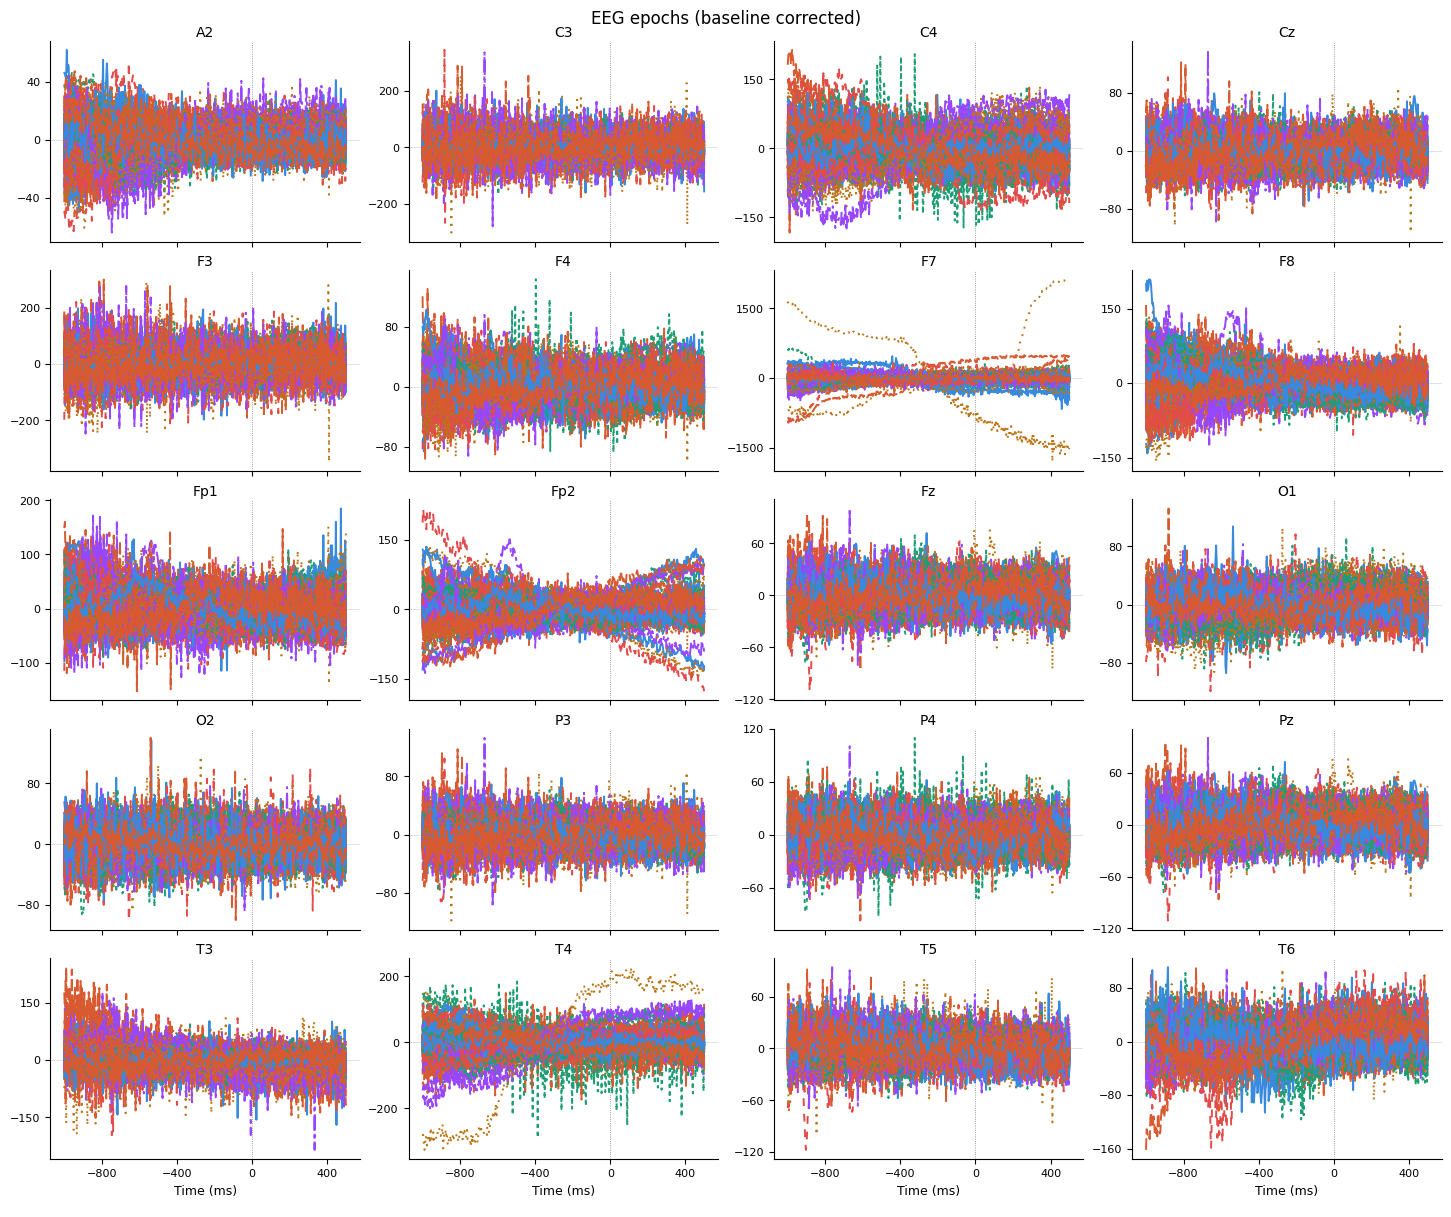

In [106]:
plot_epochs(marker_eegs, baseline_correction=True)

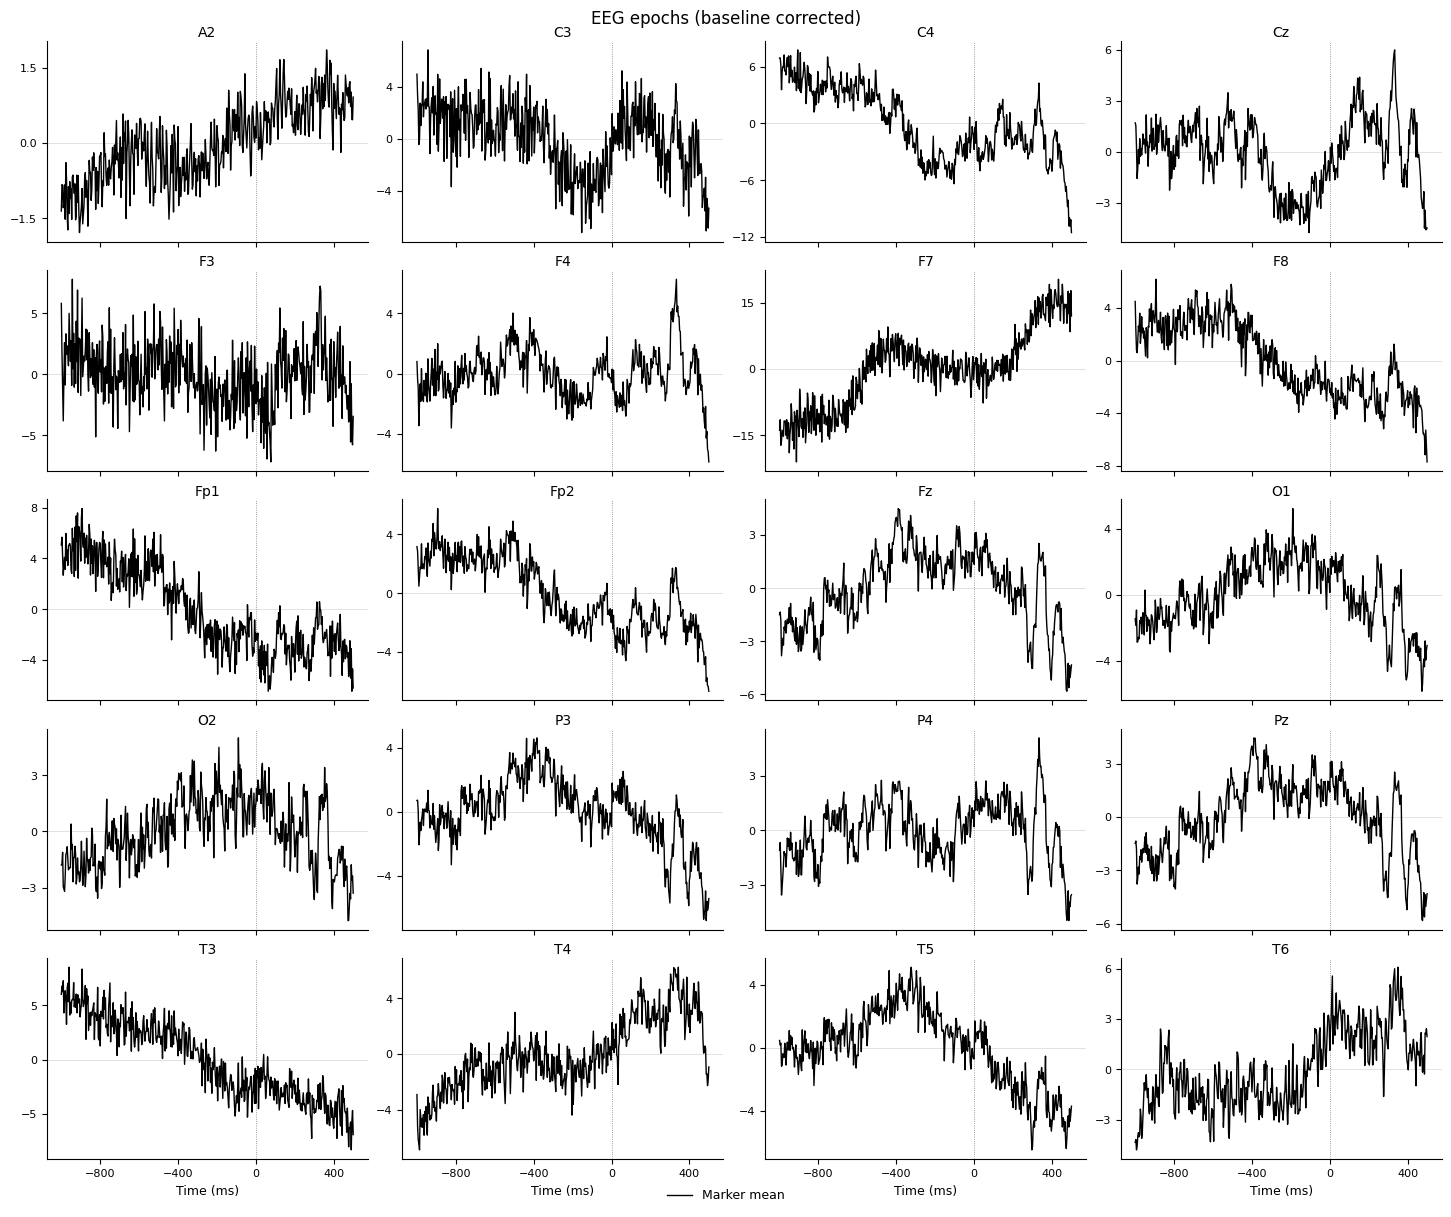

In [107]:
plot_epochs(marker_eegs, baseline_correction=True, plot_mean=True)